## Task 1 Baseline VAE and training:

In [1]:
import google
google.colab.drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from __future__ import print_function
import argparse
import torch
import torch.utils.data
from torch import nn, optim
from torch.nn import functional as F
from torchvision import datasets, transforms
from torchvision.utils import save_image
import matplotlib.pyplot as plt
import os

In [16]:
output_dir = '/content/drive/MyDrive/Imperial College London/PGM/CW2/datasets/results/VAE_MNIST/'

In [3]:
# model specs

parser = argparse.ArgumentParser(description='VAE MNIST Example')
parser.add_argument('--batch-size', type=int, default=128, metavar='N',
                    help='input batch size for training (default: 128)')
parser.add_argument('--epochs', type=int, default=70, metavar='N',
                    help='number of epochs to train (default: 70)')
parser.add_argument('--no-accel', action='store_true',
                    help='disables accelerator')
parser.add_argument('--seed', type=int, default=1, metavar='S',
                    help='random seed (default: 1)')
parser.add_argument('--log-interval', type=int, default=10, metavar='N',
                    help='how many batches to wait before logging training status')
args, _ = parser.parse_known_args()

torch.manual_seed(args.seed)

# Decide which device we want to run on (CUDA > MPS > CPU)
if torch.cuda.is_available():
    device = torch.device("cuda:0")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Using device:", device)

kwargs = {'num_workers': 1, 'pin_memory': True} if device.type in ["cuda", "mps"] else {}
train_loader = torch.utils.data.DataLoader(
    datasets.MNIST('../../../datasets', train=True, download=True,
                   transform=transforms.ToTensor()),
    batch_size=args.batch_size, shuffle=True, **kwargs)
test_loader = torch.utils.data.DataLoader(
    datasets.MNIST('../../../datasets', train=False, transform=transforms.ToTensor()),
    batch_size=args.batch_size, shuffle=False, **kwargs)


Using device: cuda:0


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 499kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.57MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.7MB/s]


In [4]:
class VAE(nn.Module):
    def __init__(self):
        super(VAE, self).__init__()

        self.encode1 = nn.Linear(784, 400)
        self.encode2 = nn.Linear(400, 200)
        self.mu_layer = nn.Linear(200, 20)
        self.logvar_layer = nn.Linear(200, 20)

        self.decode1 = nn.Linear(20, 200)
        self.decode2 = nn.Linear(200, 400)
        self.final = nn.Linear(400, 784)

    def encode(self, x):
        h1 = F.relu(self.encode1(x))
        h1 = F.relu(self.encode2(h1))
        return self.mu_layer(h1), self.logvar_layer(h1)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5*logvar)
        eps = torch.randn_like(std)
        return mu + eps*std

    def decode(self, z):
        h3 = F.relu(self.decode1(z))
        h3 = F.relu(self.decode2(h3))
        return torch.sigmoid(self.final(h3))

    def forward(self, x):
        mu_value, logvar_value = self.encode(x.view(-1, 784))
        z = self.reparameterize(mu_value, logvar_value)
        self.mu = mu_value
        self.logvar = logvar_value
        return self.decode(z), mu_value, logvar_value

In [5]:
# functions

# Reconstruction + KL divergence losses summed over all elements and batch
def loss_function(recon_x, x, mu, logvar):
    BCE = F.binary_cross_entropy(recon_x, x.view(-1, 784), reduction='sum')

    # 0.5 * sum(1 + log(sigma^2) - mu^2 - sigma^2)
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    return BCE, KLD


def train(epoch, model):
    model.train()
    train_loss = 0
    bce_loss = 0
    kld_loss = 0
    for batch_idx, (data, _) in enumerate(train_loader):
        data = data.to(device)
        optimizer.zero_grad()
        recon_batch, mu, logvar = model(data)
        bce, kld = loss_function(recon_batch, data, mu, logvar)
        (bce+kld).backward()

        bce_loss += bce.item()
        kld_loss += kld.item()
        train_loss += (bce+kld).item()
        optimizer.step()
        '''
        if batch_idx % args.log_interval == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader),
                loss.item() / len(data)))
        '''
    avg_train_loss = train_loss / len(train_loader.dataset)
    avg_bce_loss = bce_loss / len(train_loader.dataset)
    avg_kld_loss = kld_loss / len(train_loader.dataset)

    '''
    print('====> Epoch: {} Average loss: {:.4f}'.format(
          epoch, train_loss / len(train_loader.dataset)))
    '''
    return avg_train_loss, avg_bce_loss, avg_kld_loss


def test(epoch, model):
    model.eval()
    test_loss = 0
    with torch.no_grad():
        for i, (data, _) in enumerate(test_loader):
            data = data.to(device)
            recon_batch, mu, logvar = model(data)
            bce_test, kld_test = loss_function(recon_batch, data, mu, logvar)
            test_loss += (bce_test + kld_test).item()

    test_loss /= len(test_loader.dataset)
    #print('====> Test set loss: {:.4f}'.format(test_loss))
    return test_loss

In [ ]:
model = VAE().to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3)

In [ ]:
train_losses = []
train_bce_losses = []
train_kld_losses = []
test_losses = []

for epoch in range(1, args.epochs + 1):
    avg_loss, avg_bce_loss, avg_kld_loss = train(epoch, model)
    train_losses.append(avg_loss)
    train_bce_losses.append(avg_bce_loss)
    train_kld_losses.append(avg_kld_loss)
    test_loss = test(epoch, model)
    test_losses.append(test_loss)

    print('====> Epoch: {} Average loss: {:.4f} Test loss {}'.format(
          epoch, avg_loss, test_loss))

====> Epoch: 1 Average loss: 182.9076 Test loss 143.62702416992187
====> Epoch: 2 Average loss: 132.4748 Test loss 122.49552634277343
====> Epoch: 3 Average loss: 119.5439 Test loss 115.28369440917969
====> Epoch: 4 Average loss: 114.1942 Test loss 111.51315518798827
====> Epoch: 5 Average loss: 111.1298 Test loss 109.14104594726562
====> Epoch: 6 Average loss: 109.0746 Test loss 107.43423701171875
====> Epoch: 7 Average loss: 107.4540 Test loss 106.4366332397461
====> Epoch: 8 Average loss: 106.2731 Test loss 105.26011722412109
====> Epoch: 9 Average loss: 105.2786 Test loss 104.56941689453124
====> Epoch: 10 Average loss: 104.4462 Test loss 103.82877255859376
====> Epoch: 11 Average loss: 103.8409 Test loss 103.37892209472656
====> Epoch: 12 Average loss: 103.2771 Test loss 103.01771710205078
====> Epoch: 13 Average loss: 102.7884 Test loss 102.618866796875
====> Epoch: 14 Average loss: 102.3722 Test loss 102.13728596191406
====> Epoch: 15 Average loss: 101.9643 Test loss 102.4301796

In [ ]:
output_dir = '/content/drive/MyDrive/Imperial College London/PGM/CW2/datasets/results/VAE_MNIST/'
os.makedirs(output_dir, exist_ok=True)

torch.save(model.state_dict(), output_dir+ 'model_weights.pth')

In [ ]:
my_model = VAE().to(device)
state = torch.load('/content/drive/MyDrive/Imperial College London/PGM/CW2/datasets/results/VAE_MNIST/' + "model_weights.pth", map_location=device, weights_only=False)
my_model.load_state_dict(state)
my_model.eval()

VAE(
  (encode1): Linear(in_features=784, out_features=400, bias=True)
  (encode2): Linear(in_features=400, out_features=200, bias=True)
  (mu_layer): Linear(in_features=200, out_features=20, bias=True)
  (logvar_layer): Linear(in_features=200, out_features=20, bias=True)
  (decode1): Linear(in_features=20, out_features=200, bias=True)
  (decode2): Linear(in_features=200, out_features=400, bias=True)
  (final): Linear(in_features=400, out_features=784, bias=True)
)

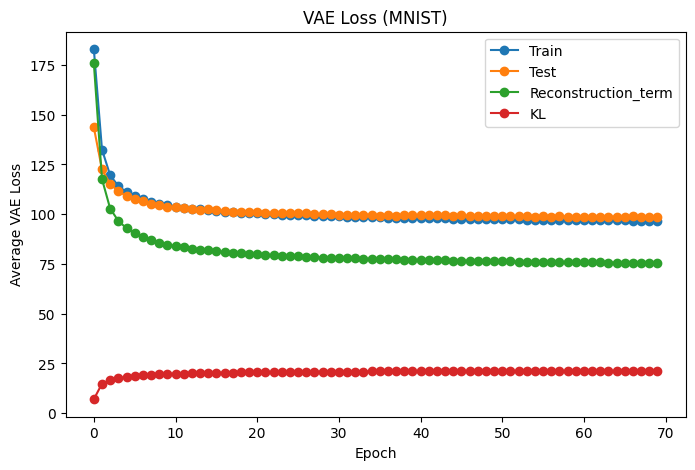

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(train_losses, '-o')
plt.plot(test_losses, '-o')
plt.plot(train_bce_losses, '-o')
plt.plot(train_kld_losses, '-o')

plt.xlabel("Epoch")
plt.ylabel("Average VAE Loss")
plt.title("VAE Loss (MNIST)")
plt.legend(["Train", "Test", "Reconstruction_term", "KL"])
plt.savefig(output_dir + 'VAE_training_loss.png')
plt.show()



## Task 2 Reconstruction vs generation

In [ ]:
seed = 42

torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

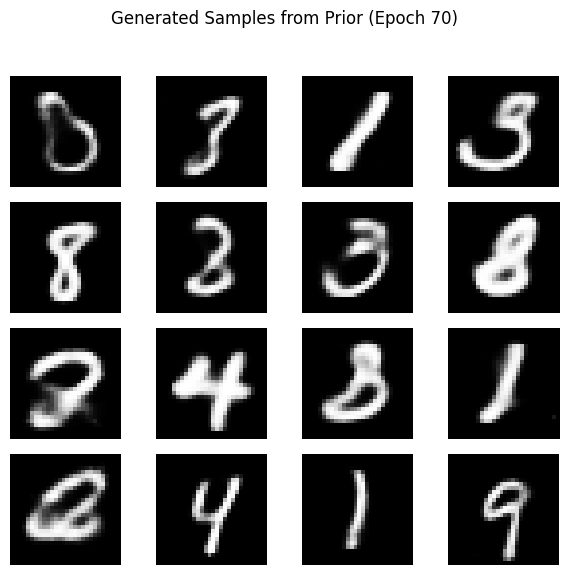

In [ ]:
sample = torch.randn(16, 20).to(device)
sample = my_model.decode(sample).cpu()
save_image(sample.view(16, 1, 28, 28), output_dir + 'sample_' + str(epoch) + '.png')

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
axes = axes.flatten()

for i in range(16):
    ax = axes[i]
    img = sample[i].view(28, 28).detach().numpy()
    ax.imshow(img, cmap='gray')
    ax.axis('off')

plt.suptitle('Generated Samples from Prior (Epoch ' + str(epoch) + ')')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(output_dir + 'prior')
plt.show()

In [6]:
dataset = test_loader.dataset
indices = torch.randperm(len(dataset))[:16]

sample_a = torch.stack([dataset[i][0] for i in indices]) # (16, 1, 28, 28)

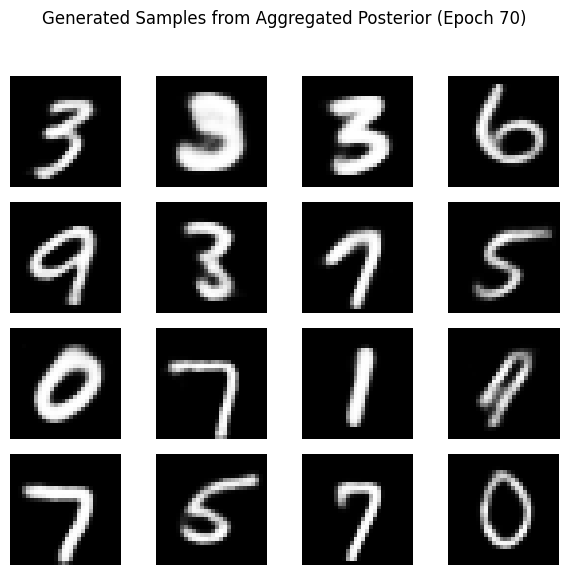

In [ ]:
sample_flat = sample_a.view(16, 784).to(device)
_, mu, logvar = my_model(sample_flat)
z = mu + torch.exp(0.5*logvar) * torch.randn_like(mu)
z = my_model.decode(z)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
axes = axes.flatten()

for i in range(16):
    ax = axes[i]
    img = z[i].view(28, 28).detach().cpu().numpy()
    ax.imshow(img, cmap='gray')
    ax.axis('off')

plt.suptitle('Generated Samples from Aggregated Posterior (Epoch ' + str(epoch) + ')')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(output_dir + 'aggregated posterior')
plt.show()


## Task 3 Comparing the prior and the aggregated posterior

In [ ]:
from sklearn.manifold import TSNE
import numpy as np

my_model.eval()
all_z = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.view(-1, 784).to(device)
        mu, logvar = my_model.encode(images)
        all_z.append(mu.cpu())
        all_labels.append(labels)

z_posterior = torch.cat(all_z, dim=0).numpy()
labels = torch.cat(all_labels, dim=0).numpy()

z_prior = torch.randn(len(z_posterior), 20).numpy()

z_combined = np.vstack([z_posterior, z_prior])
tsne = TSNE(n_components=2, init='pca', random_state=42)
z_2d = tsne.fit_transform(z_combined)

z_posterior_2d = z_2d[:len(z_posterior)]
z_prior_2d = z_2d[len(z_posterior):]

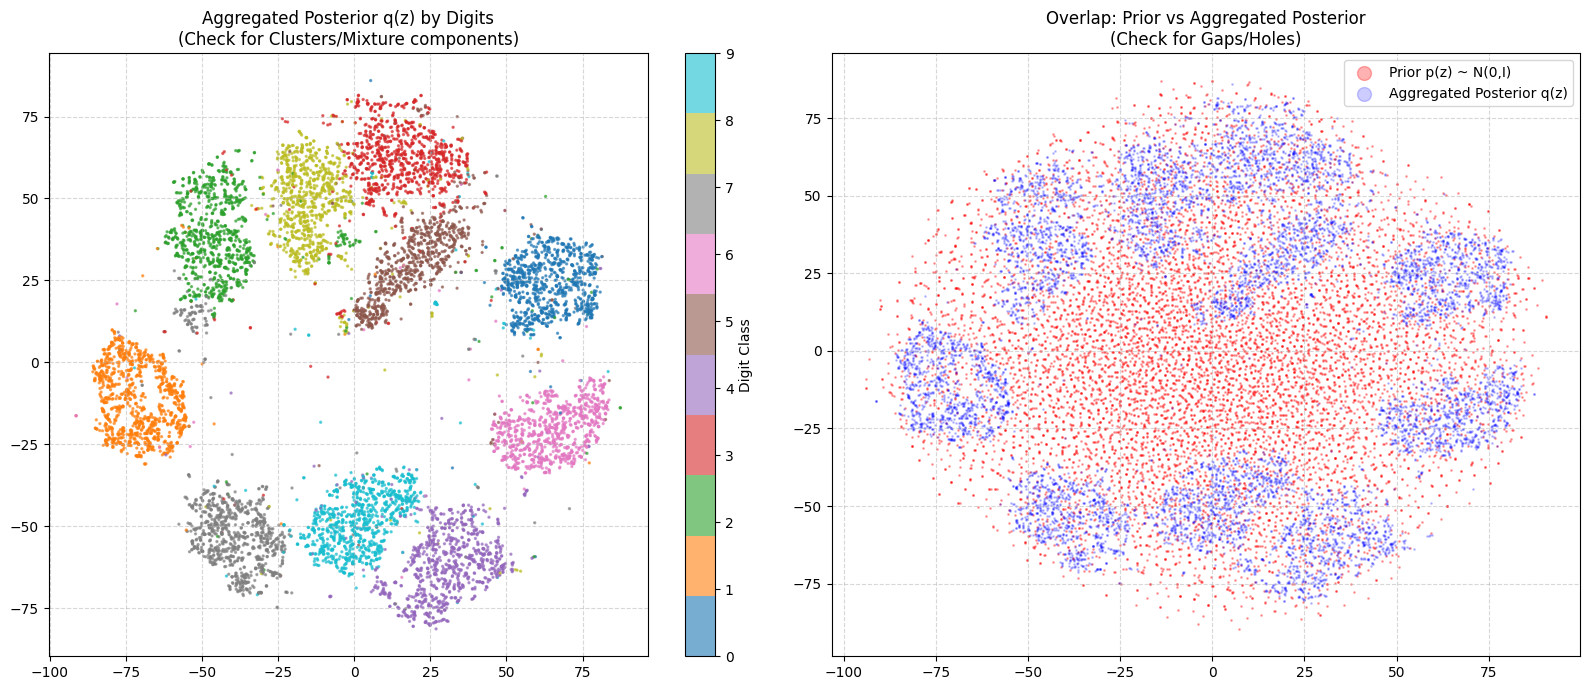

In [ ]:
plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)
scatter = plt.scatter(z_posterior_2d[:, 0], z_posterior_2d[:, 1],
                      c=labels, cmap='tab10', s=2, alpha=0.6)
plt.colorbar(scatter, label='Digit Class')
plt.title('Aggregated Posterior q(z) by Digits\n(Check for Clusters/Mixture components)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)

plt.scatter(z_prior_2d[:, 0], z_prior_2d[:, 1],
            c='red', s=1, alpha=0.3, label='Prior p(z) ~ N(0,I)')

plt.scatter(z_posterior_2d[:, 0], z_posterior_2d[:, 1],
            c='blue', s=1, alpha=0.2, label='Aggregated Posterior q(z)')
plt.legend(markerscale=10)
plt.title('Overlap: Prior vs Aggregated Posterior\n(Check for Gaps/Holes)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(output_dir + 'prior_vs_posterior.png')
plt.show()

In [ ]:
mu_set = []
var_set = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.view(-1, 784).to(device)
        mu, logvar = my_model.encode(images)
        var = torch.exp(logvar)
        mu_set.append(mu.cpu())
        var_set.append(var.cpu())

mu_set = torch.cat(mu_set, dim=0)
var_set = torch.cat(var_set, dim=0)

posterior_mean = torch.mean(mu_set, dim=0)
sum_mean = torch.mean(posterior_mean ** 2)

# varz = E(var(z|x))+var(E(z|x))
p1 = torch.mean(var_set, dim=0)
p2 = torch.var(mu_set, dim=0)

posterior_var = p1 + p2
sum_posterior_var = torch.mean(posterior_var)

print(f"The mean of posterior mean is")
print(posterior_mean.numpy())
print(f"The var of posterior variance is")
print(posterior_var.numpy())
print(f"The mean of posterior_var is {sum_posterior_var.numpy()}")
print(f"The distance pf posterior_mean is {sum_mean.numpy()}")




The mean of posterior mean is
[-0.01625573 -0.02128693  0.02393476  0.03277608 -0.02259988 -0.04281112
 -0.02034264 -0.07257681 -0.03540133  0.00730507  0.022188    0.05641414
 -0.05416318  0.00038926  0.0346089   0.02161449 -0.10429352  0.08514477
  0.01560785  0.13425773]
The var of posterior variance is
[0.9737494  0.9433626  0.99077505 0.9978516  0.9578848  0.9853433
 0.976138   1.0014286  0.9680452  0.9838334  0.9558463  0.95410097
 0.984212   0.9692795  0.97476894 1.0362225  1.033065   0.97826076
 1.0059745  1.0303986 ]
The mean of posterior_var is 0.985027015209198
The distance pf posterior_mean is 0.002818252192810178


In [25]:
# Wasserstein metric between standard Gaussian and the aggregated one
def wasserstein (mu: torch.Tensor, logvar: torch.Tensor):

  var = torch.exp(logvar)
  # mu ** 2 + tr(1 + sigma - 2 * sigma ** 0.5)
  pmu = torch.sum(mu ** 2)
  pvar = torch.sum(1.0 + var - 2 * var ** 0.5)
  return (pmu + pvar).item()

In [ ]:
wasserstein(posterior_mean, posterior_var)

8.16930866241455

## Task 4 Reconstruction and regularisation

In [ ]:
output_dir = '/content/drive/MyDrive/Imperial College London/PGM/CW2/datasets/results/VAE_MNIST/'

In [ ]:
def reg_train(epoch, beta, model):
    model.train()
    train_loss = 0
    bce_loss = 0
    kld_loss = 0
    for batch_idx, (data, _) in enumerate(train_loader):
        data = data.to(device)
        optimizer.zero_grad()
        recon_batch, mu, logvar = model(data)
        bce, kld = loss_function(recon_batch, data, mu, logvar)
        (bce + beta * kld).backward()

        bce_loss += bce.item()
        kld_loss += kld.item()
        train_loss += (bce+ beta * kld).item()
        optimizer.step()
        '''
        if batch_idx % args.log_interval == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader),
                loss.item() / len(data)))
        '''
    avg_train_loss = train_loss / len(train_loader.dataset)
    avg_bce_loss = bce_loss / len(train_loader.dataset)
    avg_kld_loss = kld_loss / len(train_loader.dataset)

    '''
    print('====> Epoch: {} Average loss: {:.4f}'.format(
          epoch, train_loss / len(train_loader.dataset)))
    '''
    return avg_train_loss, avg_bce_loss, avg_kld_loss


def reg_test(epoch, beta, model):
    model.eval()
    test_loss = 0
    with torch.no_grad():
        for i, (data, _) in enumerate(test_loader):
            data = data.to(device)
            recon_batch, mu, logvar = model(data)
            bce_test, kld_test = loss_function(recon_batch, data, mu, logvar)
            test_loss += (bce_test + beta * kld_test).item()

    test_loss /= len(test_loader.dataset)
    #print('====> Test set loss: {:.4f}'.format(test_loss))
    return test_loss

In [ ]:
model1 = VAE().to(device)
optimizer = optim.Adam(model1.parameters(), lr=1e-3)

# beta = 0.001
train_losses_1 = []
train_bce_losses_1 = []
train_kld_losses_1 = []
test_losses_1 = []

for epoch in range(1, args.epochs + 1):
    avg_loss_1, avg_bce_loss_1, avg_kld_loss_1 = reg_train(epoch, beta = 1e-3, model = model1)
    train_losses_1.append(avg_loss_1)
    train_bce_losses_1.append(avg_bce_loss_1)
    train_kld_losses_1.append(avg_kld_loss_1)
    test_loss_1 = reg_test(epoch, beta = 1e-3, model = model1)
    test_losses_1.append(test_loss_1)

    print('====> Epoch: {} Average loss: {:.4f} Test loss {}'.format(
          epoch, avg_loss_1, test_loss_1))

====> Epoch: 1 Average loss: 153.5373 Test loss 104.62447764892578
====> Epoch: 2 Average loss: 94.7088 Test loss 86.44135394287109
====> Epoch: 3 Average loss: 83.0488 Test loss 78.63107117919922
====> Epoch: 4 Average loss: 76.8730 Test loss 74.41721290283203
====> Epoch: 5 Average loss: 73.0682 Test loss 71.51506673583984
====> Epoch: 6 Average loss: 70.6045 Test loss 69.43571783447265
====> Epoch: 7 Average loss: 69.1190 Test loss 68.74699509277343
====> Epoch: 8 Average loss: 68.0858 Test loss 67.8702874633789
====> Epoch: 9 Average loss: 67.3135 Test loss 67.10879432983398
====> Epoch: 10 Average loss: 66.6591 Test loss 67.06475261230469
====> Epoch: 11 Average loss: 66.1629 Test loss 66.4134992553711
====> Epoch: 12 Average loss: 65.7501 Test loss 66.17952769775391
====> Epoch: 13 Average loss: 65.3717 Test loss 65.73994514160157
====> Epoch: 14 Average loss: 65.0184 Test loss 65.66488071899414
====> Epoch: 15 Average loss: 64.7505 Test loss 65.34804295043945
====> Epoch: 16 Ave

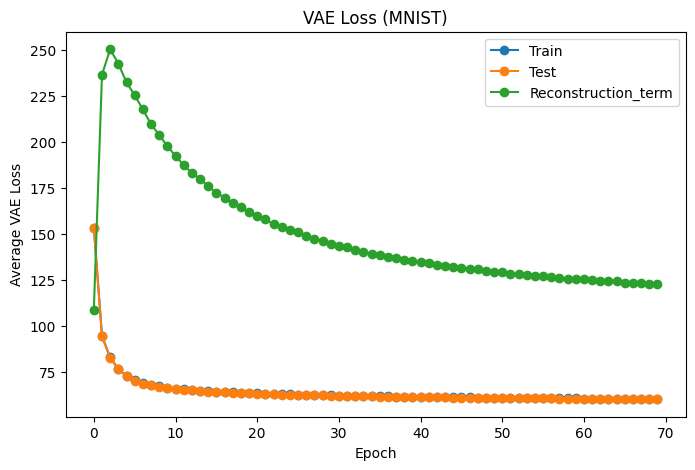

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(train_losses_1, '-o')
#plt.plot(test_losses_1, '-o')
plt.plot(train_bce_losses_1, '-o')
plt.plot(train_kld_losses_1, '-o')

plt.xlabel("Epoch")
plt.ylabel("Average VAE Loss")
plt.title("VAE Loss (MNIST)")
plt.legend(["Train", "Test", "Reconstruction_term", "KL"])
#plt.savefig(output_dir + 'VAE_training_loss.png')
plt.show()

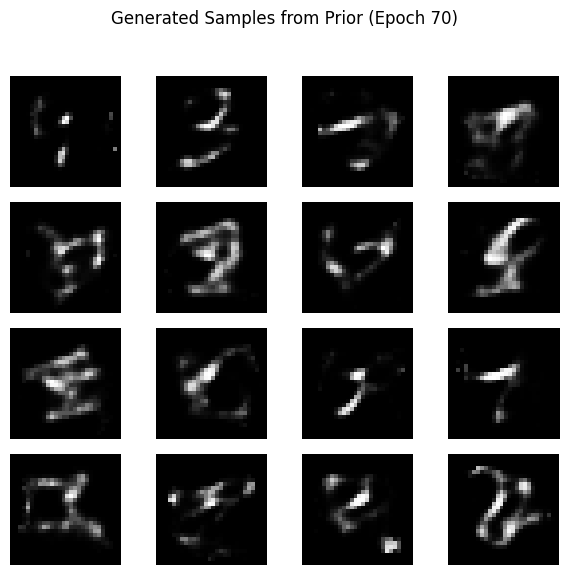

In [ ]:
sample = torch.randn(16, 20).to(device)
sample = model1.decode(sample).cpu()
#save_image(sample.view(16, 1, 28, 28), output_dir + 'sample_' + str(epoch) + '.png')

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
axes = axes.flatten()

for i in range(16):
    ax = axes[i]
    img = sample[i].view(28, 28).detach().numpy()
    ax.imshow(img, cmap='gray')
    ax.axis('off')

plt.suptitle('Generated Samples from Prior (Epoch ' + str(epoch) + ')')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(output_dir + 'prior low beta')
plt.show()

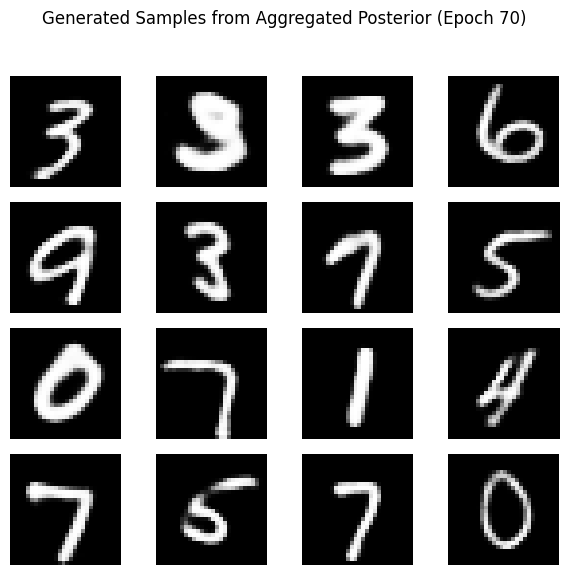

In [ ]:
sample_flat = sample_a.view(16, 784).to(device)
_, mu, logvar = model1(sample_flat)
z = mu + torch.exp(0.5*logvar) * torch.randn_like(mu)
z = model1.decode(z)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
axes = axes.flatten()

for i in range(16):
    ax = axes[i]
    img = z[i].view(28, 28).detach().cpu().numpy()
    ax.imshow(img, cmap='gray')
    ax.axis('off')

plt.suptitle('Generated Samples from Aggregated Posterior (Epoch ' + str(epoch) + ')')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(output_dir + 'aggregated posterior low beta')
plt.show()

In [ ]:
print(wasserstein(mu, logvar))

1524.65234375


In [ ]:
model2 = VAE().to(device)
optimizer = optim.Adam(model2.parameters(), lr=1e-3)

# beta = 1000
train_losses_2 = []
train_bce_losses_2 = []
train_kld_losses_2 = []
test_losses_2 = []

for epoch in range(1, args.epochs + 1):
    avg_loss_2, avg_bce_loss_2, avg_kld_loss_2 = reg_train(epoch, beta = 1000, model = model2)
    train_losses_2.append(avg_loss_2)
    train_bce_losses_2.append(avg_bce_loss_2)
    train_kld_losses_2.append(avg_kld_loss_2)
    test_loss_2 = reg_test(epoch, beta = 1000, model = model2)
    test_losses_2.append(test_loss_2)

    print('====> Epoch: {} Average loss: {:.4f} Test loss {}'.format(
          epoch, avg_loss_2, test_loss_2))

====> Epoch: 1 Average loss: 214.6677 Test loss 207.18640224609376
====> Epoch: 2 Average loss: 206.9812 Test loss 206.34693049316405
====> Epoch: 3 Average loss: 206.6275 Test loss 206.31058374023436
====> Epoch: 4 Average loss: 206.5214 Test loss 206.31500080566406
====> Epoch: 5 Average loss: 206.4446 Test loss 206.07214587402345
====> Epoch: 6 Average loss: 206.3825 Test loss 205.9885550048828
====> Epoch: 7 Average loss: 206.3081 Test loss 205.94618994140626
====> Epoch: 8 Average loss: 206.2878 Test loss 206.01225864257813
====> Epoch: 9 Average loss: 206.2437 Test loss 206.0741897216797
====> Epoch: 10 Average loss: 206.2083 Test loss 206.00766843261718
====> Epoch: 11 Average loss: 206.1934 Test loss 205.9722274902344
====> Epoch: 12 Average loss: 206.1586 Test loss 205.9070328125
====> Epoch: 13 Average loss: 206.1542 Test loss 205.85365842285157
====> Epoch: 14 Average loss: 206.1461 Test loss 205.93293471679686
====> Epoch: 15 Average loss: 206.1405 Test loss 205.93515930175

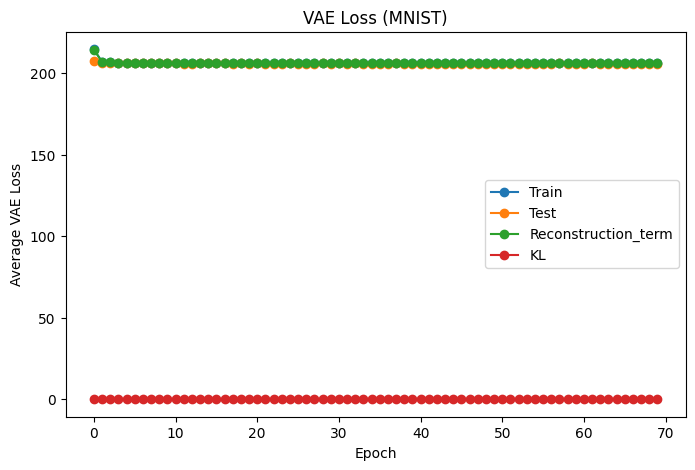

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(train_losses_2, '-o')
plt.plot(test_losses_2, '-o')
plt.plot(train_bce_losses_2, '-o')
plt.plot(train_kld_losses_2, '-o')

plt.xlabel("Epoch")
plt.ylabel("Average VAE Loss")
plt.title("VAE Loss (MNIST)")
plt.legend(["Train", "Test", "Reconstruction_term", "KL"])
#plt.savefig(output_dir + 'VAE_training_loss.png')
plt.show()

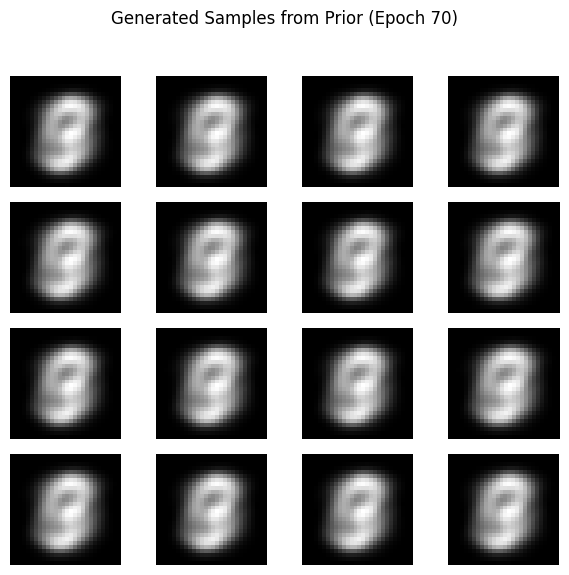

In [ ]:
sample = torch.randn(16, 20).to(device)
sample = model2.decode(sample).cpu()
#save_image(sample.view(16, 1, 28, 28), output_dir + 'sample_' + str(epoch) + '.png')

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
axes = axes.flatten()

for i in range(16):
    ax = axes[i]
    img = sample[i].view(28, 28).detach().numpy()
    ax.imshow(img, cmap='gray')
    ax.axis('off')

plt.suptitle('Generated Samples from Prior (Epoch ' + str(epoch) + ')')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(output_dir + 'prior high beta')
plt.show()

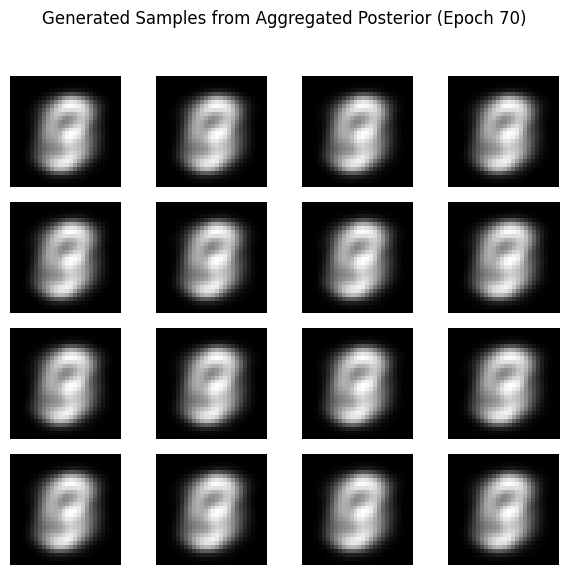

In [ ]:
sample_flat = sample_a.view(16, 784).to(device)
_, mu, logvar = model2(sample_flat)
z = mu + torch.exp(0.5*logvar) * torch.randn_like(mu)
z = model2.decode(z)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
axes = axes.flatten()

for i in range(16):
    ax = axes[i]
    img = z[i].view(28, 28).detach().cpu().numpy()
    ax.imshow(img, cmap='gray')
    ax.axis('off')

plt.suptitle('Generated Samples from Aggregated Posterior (Epoch ' + str(epoch) + ')')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(output_dir + 'aggregated posterior high beta')
plt.show()

In [ ]:
print(wasserstein(mu, logvar))

1.4794100934523158e-05


In [ ]:
model3 = VAE().to(device)
optimizer = optim.Adam(model3.parameters(), lr=1e-3)

# beta = 0.1
train_losses_3 = []
train_bce_losses_3 = []
train_kld_losses_3 = []
test_losses_3 = []

for epoch in range(1, args.epochs + 1):
    avg_loss_3, avg_bce_loss_3, avg_kld_loss_3 = reg_train(epoch, beta = 0.1, model = model3)
    train_losses_3.append(avg_loss_3)
    train_bce_losses_3.append(avg_bce_loss_3)
    train_kld_losses_3.append(avg_kld_loss_3)
    test_loss_3 = reg_test(epoch, beta = 0.1, model = model3)
    test_losses_3.append(test_loss_3)

    print('====> Epoch: {} Average loss: {:.4f} Test loss {}'.format(
          epoch, avg_loss_3, test_loss_3))

====> Epoch: 1 Average loss: 161.3261 Test loss 113.26604669189453
====> Epoch: 2 Average loss: 102.2656 Test loss 92.72775991210938
====> Epoch: 3 Average loss: 89.0712 Test loss 84.5890172241211
====> Epoch: 4 Average loss: 82.7691 Test loss 79.9890166015625
====> Epoch: 5 Average loss: 79.2368 Test loss 77.64203608398438
====> Epoch: 6 Average loss: 76.9957 Test loss 75.81378487548828
====> Epoch: 7 Average loss: 75.5328 Test loss 74.73070045166016
====> Epoch: 8 Average loss: 74.5327 Test loss 74.29729205322266
====> Epoch: 9 Average loss: 73.7862 Test loss 73.64462628173828
====> Epoch: 10 Average loss: 73.1261 Test loss 73.04325441894531
====> Epoch: 11 Average loss: 72.6301 Test loss 72.94104265136718
====> Epoch: 12 Average loss: 72.2068 Test loss 72.27908908691406
====> Epoch: 13 Average loss: 71.8550 Test loss 72.19835692138672
====> Epoch: 14 Average loss: 71.5460 Test loss 72.008733203125
====> Epoch: 15 Average loss: 71.2529 Test loss 71.60026180419922
====> Epoch: 16 Aver

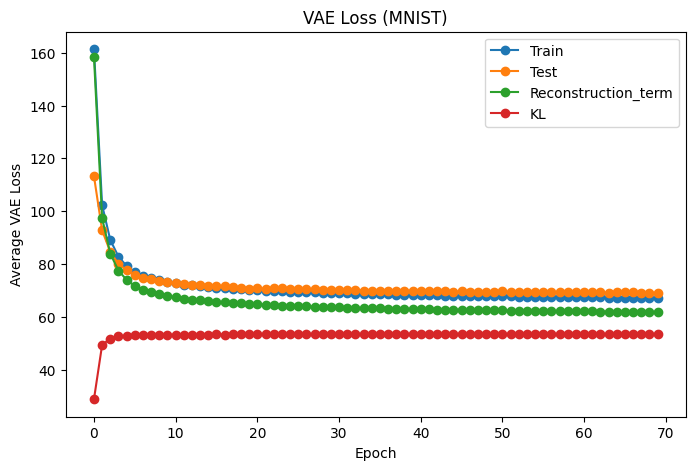

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(train_losses_3, '-o')
plt.plot(test_losses_3, '-o')
plt.plot(train_bce_losses_3, '-o')
plt.plot(train_kld_losses_3, '-o')

plt.xlabel("Epoch")
plt.ylabel("Average VAE Loss")
plt.title("VAE Loss (MNIST)")
plt.legend(["Train", "Test", "Reconstruction_term", "KL"])
#plt.savefig(output_dir + 'VAE_training_loss.png')
plt.show()

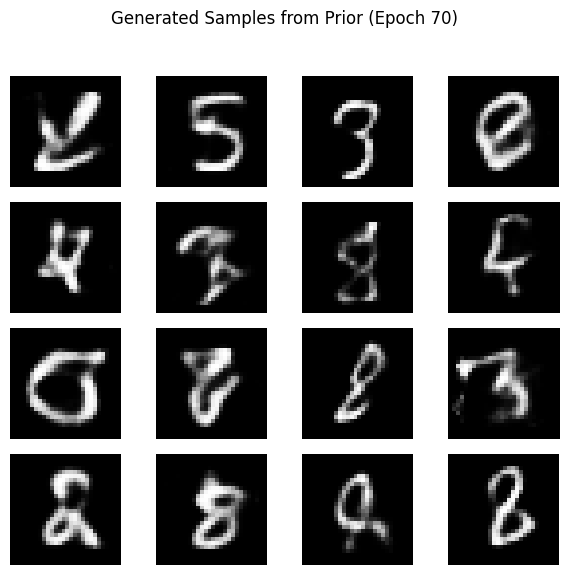

In [ ]:
sample = torch.randn(16, 20).to(device)
sample = model3.decode(sample).cpu()
#save_image(sample.view(16, 1, 28, 28), output_dir + 'sample_' + str(epoch) + '.png')

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
axes = axes.flatten()

for i in range(16):
    ax = axes[i]
    img = sample[i].view(28, 28).detach().numpy()
    ax.imshow(img, cmap='gray')
    ax.axis('off')

plt.suptitle('Generated Samples from Prior (Epoch ' + str(epoch) + ')')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(output_dir + 'prior beta 1e-1')
plt.show()

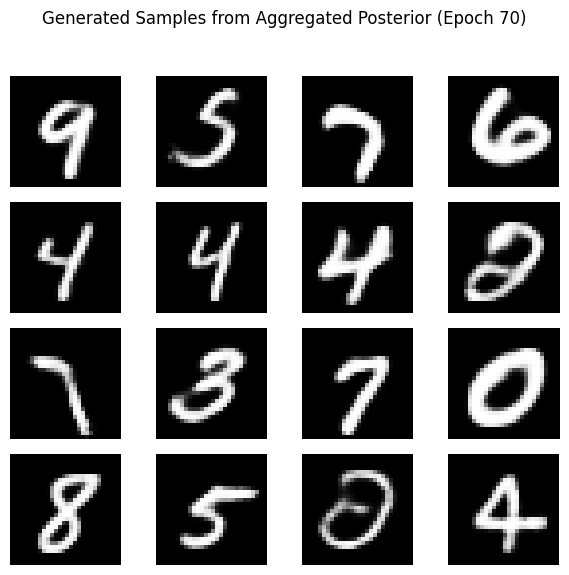

In [ ]:
sample_flat = sample_a.view(16, 784).to(device)
_, mu, logvar = model3(sample_flat)
z = mu + torch.exp(0.5*logvar) * torch.randn_like(mu)
z = model3.decode(z)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
axes = axes.flatten()

for i in range(16):
    ax = axes[i]
    img = z[i].view(28, 28).detach().cpu().numpy()
    ax.imshow(img, cmap='gray')
    ax.axis('off')

plt.suptitle('Generated Samples from Aggregated Posterior (Epoch ' + str(epoch) + ')')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(output_dir + 'aggregated posterior beta 1e-1')
plt.show()

In [ ]:
print(wasserstein(mu, logvar))

614.9107666015625


In [ ]:
model4 = VAE().to(device)
optimizer = optim.Adam(model4.parameters(), lr=1e-3)

# beta = 0.1
train_losses_4 = []
train_bce_losses_4 = []
train_kld_losses_4 = []
test_losses_4 = []

for epoch in range(1, args.epochs + 1):
    avg_loss_4, avg_bce_loss_4, avg_kld_loss_4 = reg_train(epoch, beta = 10, model = model4)
    train_losses_4.append(avg_loss_4)
    train_bce_losses_4.append(avg_bce_loss_4)
    train_kld_losses_4.append(avg_kld_loss_4)
    test_loss_4 = reg_test(epoch, beta = 10, model = model4)
    test_losses_4.append(test_loss_4)

    print('====> Epoch: {} Average loss: {:.4f} Test loss {}'.format(
          epoch, avg_loss_4, test_loss_4))

====> Epoch: 1 Average loss: 210.5885 Test loss 202.0791072265625
====> Epoch: 2 Average loss: 198.1509 Test loss 194.56271818847657
====> Epoch: 3 Average loss: 191.3371 Test loss 189.2492828125
====> Epoch: 4 Average loss: 188.1747 Test loss 187.31239741210936
====> Epoch: 5 Average loss: 186.8140 Test loss 186.25878032226564
====> Epoch: 6 Average loss: 186.0130 Test loss 184.5498918701172
====> Epoch: 7 Average loss: 185.2294 Test loss 185.017560546875
====> Epoch: 8 Average loss: 184.4842 Test loss 184.1700080078125
====> Epoch: 9 Average loss: 183.8591 Test loss 183.79982607421874
====> Epoch: 10 Average loss: 183.5246 Test loss 183.34126906738283
====> Epoch: 11 Average loss: 183.0458 Test loss 182.6590717285156
====> Epoch: 12 Average loss: 182.7860 Test loss 182.78964848632813
====> Epoch: 13 Average loss: 182.5596 Test loss 182.47117893066405
====> Epoch: 14 Average loss: 182.3501 Test loss 181.6042147949219
====> Epoch: 15 Average loss: 182.1949 Test loss 181.66513059082033


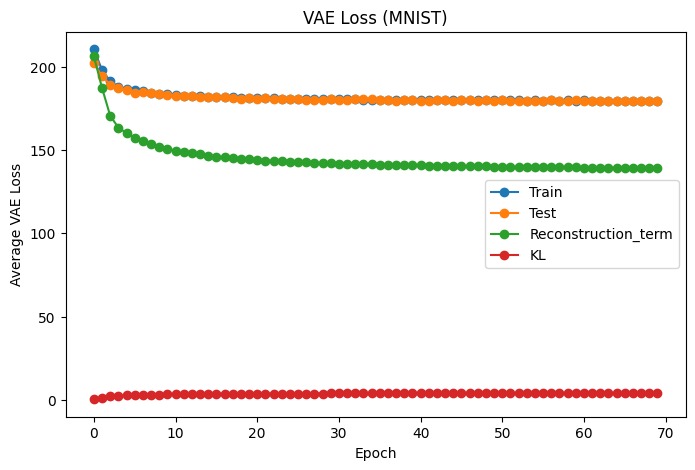

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(train_losses_4, '-o')
plt.plot(test_losses_4, '-o')
plt.plot(train_bce_losses_4, '-o')
plt.plot(train_kld_losses_4, '-o')

plt.xlabel("Epoch")
plt.ylabel("Average VAE Loss")
plt.title("VAE Loss (MNIST)")
plt.legend(["Train", "Test", "Reconstruction_term", "KL"])
#plt.savefig(output_dir + 'VAE_training_loss.png')
plt.show()

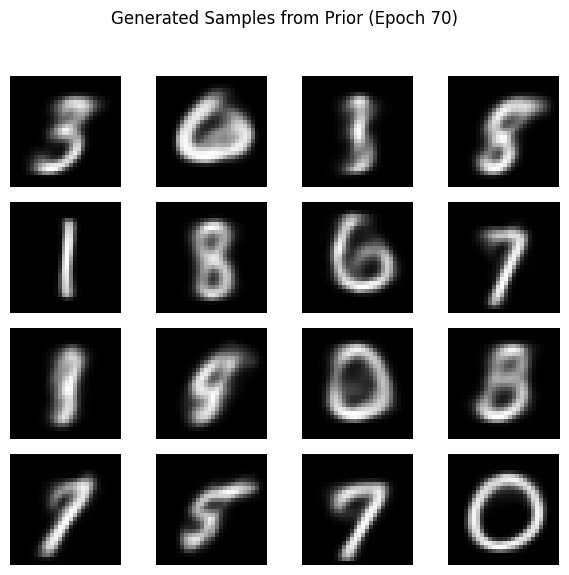

In [ ]:
sample = torch.randn(16, 20).to(device)
sample = model4.decode(sample).cpu()
#save_image(sample.view(16, 1, 28, 28), output_dir + 'sample_' + str(epoch) + '.png')

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
axes = axes.flatten()

for i in range(16):
    ax = axes[i]
    img = sample[i].view(28, 28).detach().numpy()
    ax.imshow(img, cmap='gray')
    ax.axis('off')

plt.suptitle('Generated Samples from Prior (Epoch ' + str(epoch) + ')')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(output_dir + 'prior beta 10')
plt.show()

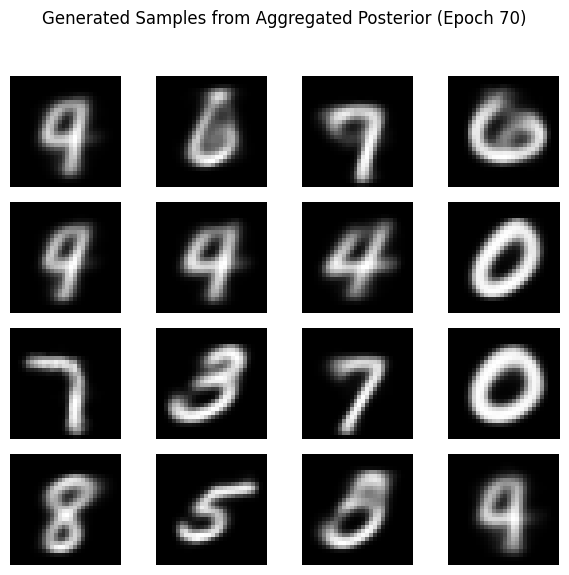

In [ ]:
sample_flat = sample_a.view(16, 784).to(device)
_, mu, logvar = model4(sample_flat)
z = mu + torch.exp(0.5*logvar) * torch.randn_like(mu)
z = model4.decode(z)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
axes = axes.flatten()

for i in range(16):
    ax = axes[i]
    img = z[i].view(28, 28).detach().cpu().numpy()
    ax.imshow(img, cmap='gray')
    ax.axis('off')

plt.suptitle('Generated Samples from Aggregated Posterior (Epoch ' + str(epoch) + ')')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(output_dir + 'aggregated posterior beta 10')
plt.show()

In [ ]:
print(wasserstein(mu, logvar))

80.258056640625


## Task 5 Improved architecture

In [7]:
class ConvVAE(nn.Module):
    def __init__(self):
        super(ConvVAE, self).__init__()

        # Encoder
        # Input: 1x28x28
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=2, padding=1) # Output: 16*14*14
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=2, padding=1) # Output: 32*7*7
        self.fc_encode = nn.Linear(32 * 7 * 7, 128)
        self.fc_mu = nn.Linear(128, 20) # Latent dimension
        self.fc_logvar = nn.Linear(128, 20) # Latent dimension

        # Decoder
        self.fc_decode = nn.Linear(20, 128)
        self.fc_upsample = nn.Linear(128, 32 * 7 * 7) # Reshape back to 32x7x7
        self.deconv1 = nn.ConvTranspose2d(in_channels=32, out_channels=16, kernel_size=3, stride=2, padding=1, output_padding=1) # Output: 16x14x14
        self.deconv2 = nn.ConvTranspose2d(in_channels=16, out_channels=1, kernel_size=3, stride=2, padding=1, output_padding=1) # Output: 1x28x28

    def encode(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = x.view(-1, 32 * 7 * 7) # Flatten for linear layers
        x = F.relu(self.fc_encode(x))
        return self.fc_mu(x), self.fc_logvar(x)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        z = F.relu(self.fc_decode(z))
        z = F.relu(self.fc_upsample(z))
        z = z.view(-1, 32, 7, 7) # Reshape to 4D tensor for deconvolutional layers
        z = F.relu(self.deconv1(z))
        return torch.sigmoid(self.deconv2(z))

    def forward(self, x):
        mu, logvar = self.encode(x) # Input x is already 1x28x28
        z = self.reparameterize(mu, logvar)
        self.mu = mu
        self.logvar = logvar
        return self.decode(z).view(-1, 28 * 28), mu, logvar

In [12]:
model_cov = ConvVAE().to(device)
optimizer = optim.Adam(model_cov.parameters(), lr=1e-3)

In [13]:
import time

train_losses_cov = []
train_bce_losses_cov = []
train_kld_losses_cov = []
test_losses_cov = []

start_time = time.time()



for epoch in range(1, args.epochs + 1):
    avg_loss_cov, avg_bce_loss_cov, avg_kld_loss_cov = train(epoch, model_cov)
    train_losses_cov.append(avg_loss_cov)
    train_bce_losses_cov.append(avg_bce_loss_cov)
    train_kld_losses_cov.append(avg_kld_loss_cov)
    test_loss_cov = test(epoch, model_cov)
    test_losses_cov.append(test_loss_cov)

    print('====> Epoch: {} Average loss: {:.4f} Test loss {}'.format(
          epoch, avg_loss_cov, test_loss_cov))

end_time = time.time()
total_seconds = end_time - start_time
print(f"Total time: {total_seconds:.2f}s")

====> Epoch: 1 Average loss: 209.3820 Test loss 152.04129467773438
====> Epoch: 2 Average loss: 135.8248 Test loss 125.0515183959961
====> Epoch: 3 Average loss: 120.3877 Test loss 115.26114599609375
====> Epoch: 4 Average loss: 114.0919 Test loss 111.69319310302734
====> Epoch: 5 Average loss: 111.1847 Test loss 109.17325540771485
====> Epoch: 6 Average loss: 109.2223 Test loss 107.61702177734375
====> Epoch: 7 Average loss: 107.6703 Test loss 106.35528541259765
====> Epoch: 8 Average loss: 106.5902 Test loss 105.85322133789063
====> Epoch: 9 Average loss: 105.7459 Test loss 104.81635522460938
====> Epoch: 10 Average loss: 105.1782 Test loss 104.74746623535157
====> Epoch: 11 Average loss: 104.7203 Test loss 103.90417991943359
====> Epoch: 12 Average loss: 104.2385 Test loss 103.3353875
====> Epoch: 13 Average loss: 103.8623 Test loss 103.40168059082032
====> Epoch: 14 Average loss: 103.5704 Test loss 102.91281945800782
====> Epoch: 15 Average loss: 103.2708 Test loss 103.157965368652

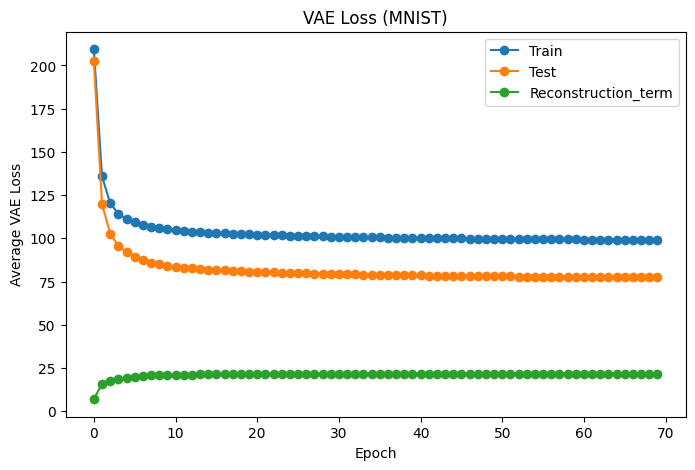

In [18]:
plt.figure(figsize=(8,5))
plt.plot(train_losses_cov, '-o')
#plt.plot(test_losses_cov, '-o')
plt.plot(train_bce_losses_cov, '-o')
plt.plot(train_kld_losses_cov, '-o')

plt.xlabel("Epoch")
plt.ylabel("Average VAE Loss")
plt.title("VAE Loss (MNIST)")
plt.legend(["Train", "Test", "Reconstruction_term", "KL"])
plt.savefig(output_dir + 'VAE_training_loss_conv.png')
plt.show()

In [19]:
output_dir_cov = '/content/drive/MyDrive/Imperial College London/PGM/CW2/datasets/results/VAE_MNIST/'
os.makedirs(output_dir_cov, exist_ok=True)

torch.save(model_cov.state_dict(), output_dir_cov+ 'model_weights_cov.pth')

In [20]:
my_model_cov = ConvVAE().to(device)
state_cov = torch.load('/content/drive/MyDrive/Imperial College London/PGM/CW2/datasets/results/VAE_MNIST/' + "model_weights_cov.pth", map_location=device, weights_only=False)
my_model_cov.load_state_dict(state_cov)
my_model_cov.eval()

ConvVAE(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (fc_encode): Linear(in_features=1568, out_features=128, bias=True)
  (fc_mu): Linear(in_features=128, out_features=20, bias=True)
  (fc_logvar): Linear(in_features=128, out_features=20, bias=True)
  (fc_decode): Linear(in_features=20, out_features=128, bias=True)
  (fc_upsample): Linear(in_features=128, out_features=1568, bias=True)
  (deconv1): ConvTranspose2d(32, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  (deconv2): ConvTranspose2d(16, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
)

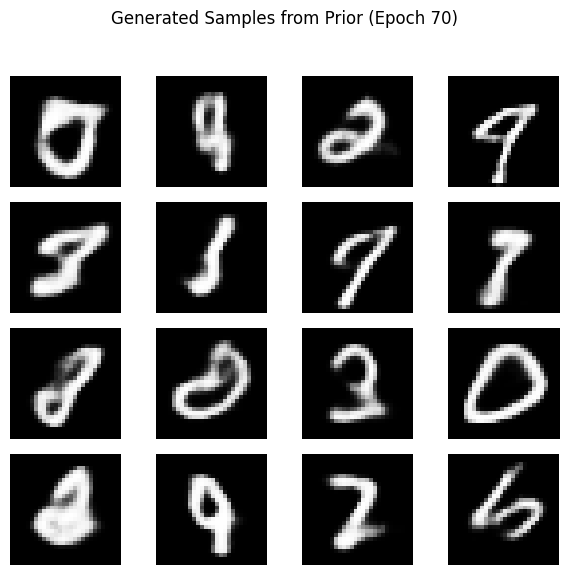

In [21]:
epoch = 70

sample = torch.randn(16, 20).to(device)
sample = my_model_cov.decode(sample).cpu()
save_image(sample.view(16, 1, 28, 28), output_dir + 'sample_' + str(epoch) + '.png')

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
axes = axes.flatten()

for i in range(16):
    ax = axes[i]
    img = sample[i].view(28, 28).detach().numpy()
    ax.imshow(img, cmap='gray')
    ax.axis('off')

plt.suptitle('Generated Samples from Prior (Epoch ' + str(epoch) + ')')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(output_dir + 'prior_convvae')
plt.show()

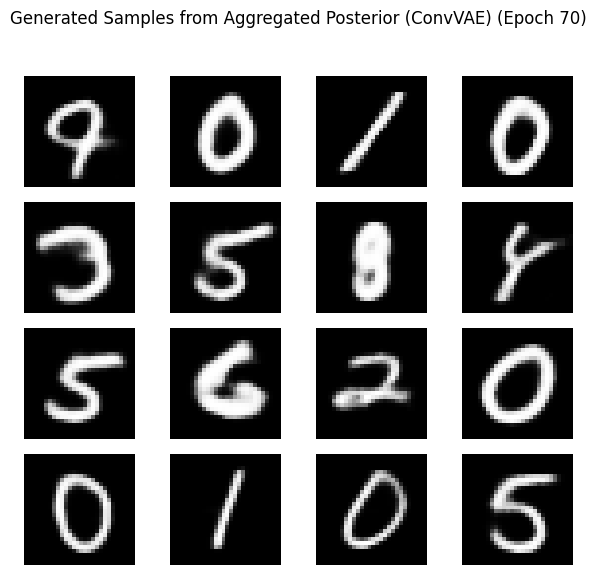

In [22]:
sample_input_cov = sample_a.to(device) # sample_a is already (16, 1, 28, 28)
_, mu, logvar = my_model_cov(sample_input_cov)
z = mu + torch.exp(0.5*logvar) * torch.randn_like(mu)
z = my_model_cov.decode(z) # Use my_model_cov for decoding

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
axes = axes.flatten()

for i in range(16):
    ax = axes[i]
    img = z[i].view(28, 28).detach().cpu().numpy()
    ax.imshow(img, cmap='gray')
    ax.axis('off')

plt.suptitle('Generated Samples from Aggregated Posterior (ConvVAE) (Epoch ' + str(epoch) + ')')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(output_dir + 'aggregated posterior_convvae')
plt.show()

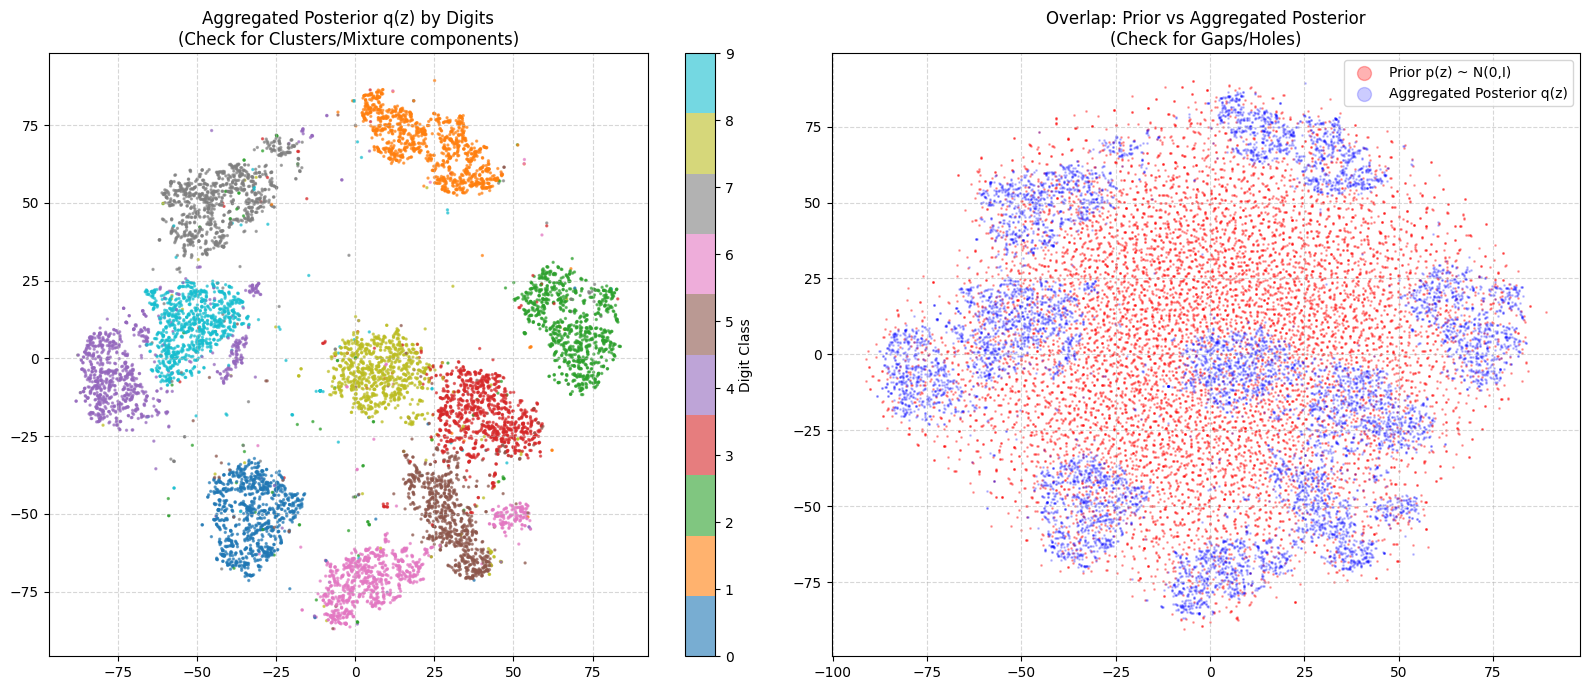

In [23]:
from sklearn.manifold import TSNE
import numpy as np

my_model_cov.eval()
all_z = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        mu, logvar = my_model_cov.encode(images)
        all_z.append(mu.cpu())
        all_labels.append(labels)

z_posterior = torch.cat(all_z, dim=0).numpy()
labels = torch.cat(all_labels, dim=0).numpy()

z_prior = torch.randn(len(z_posterior), 20).numpy()

z_combined = np.vstack([z_posterior, z_prior])
tsne = TSNE(n_components=2, init='pca', random_state=42)
z_2d = tsne.fit_transform(z_combined)

z_posterior_2d = z_2d[:len(z_posterior)]
z_prior_2d = z_2d[len(z_posterior):]


plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)
scatter = plt.scatter(z_posterior_2d[:, 0], z_posterior_2d[:, 1],
                      c=labels, cmap='tab10', s=2, alpha=0.6)
plt.colorbar(scatter, label='Digit Class')
plt.title('Aggregated Posterior q(z) by Digits\n(Check for Clusters/Mixture components)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)

plt.scatter(z_prior_2d[:, 0], z_prior_2d[:, 1],
            c='red', s=1, alpha=0.3, label='Prior p(z) ~ N(0,I)')

plt.scatter(z_posterior_2d[:, 0], z_posterior_2d[:, 1],
            c='blue', s=1, alpha=0.2, label='Aggregated Posterior q(z)')
plt.legend(markerscale=10)
plt.title('Overlap: Prior vs Aggregated Posterior\n(Check for Gaps/Holes)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(output_dir + 'prior_vs_posterior_convvae.png')
plt.show()

In [26]:
mu_set = []
var_set = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        mu, logvar = my_model_cov.encode(images)
        var = torch.exp(logvar)
        mu_set.append(mu.cpu())
        var_set.append(var.cpu())

mu_set = torch.cat(mu_set, dim=0)
var_set = torch.cat(var_set, dim=0)

posterior_mean = torch.mean(mu_set, dim=0)

# varz = E(var(z|x))+var(E(z|x))
p1 = torch.mean(var_set, dim=0)
p2 = torch.var(mu_set, dim=0)

posterior_var = p1 + p2
sum_posterior_var = torch.mean(posterior_var)

print(f"The mean of posterior mean is")
print(posterior_mean.numpy())
print(f"The distance of mean is {torch.sum(posterior_mean ** 2)}")
print(f"The var of posterior variance is")
print(posterior_var.numpy())
print(f"The mean of posterior_var is {sum_posterior_var.numpy()}")

wasserstein_metric = wasserstein (posterior_mean, posterior_var)
print(f"The Wassersstein is {wasserstein_metric}")

The mean of posterior mean is
[ 0.02248652  0.08370316 -0.02168319 -0.04368458 -0.03465949 -0.00011808
 -0.01872681  0.02289255 -0.04341693 -0.03208318 -0.03001139  0.01598108
 -0.05492037  0.02026408  0.03992018  0.01334557  0.07742328  0.04779061
 -0.06468938  0.05257177]
The distance of mean is 0.03646228089928627
The var of posterior variance is
[0.9924205  0.9768745  0.9370615  0.9711984  0.9924413  1.0118195
 0.9862782  0.97604966 1.0017433  0.9678316  0.94264066 1.0056964
 1.0172969  0.91733867 0.98500925 0.96333706 0.9239899  1.0064565
 1.021547   0.9991112 ]
The mean of posterior_var is 0.9798070192337036
The Wassersstein is 8.045031547546387


In [29]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ConvVAE1(nn.Module):
    def __init__(self):
        super(ConvVAE1, self).__init__()

        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=2, padding=1)  # Output: 16 x 14 x 14
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=2, padding=1) # Output: 32 x 7 x 7
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=2, padding=1) # Output: 64 x 4 x 4

        self.fc_encode = nn.Linear(64 * 4 * 4, 128)
        self.fc_mu = nn.Linear(128, 20)
        self.fc_logvar = nn.Linear(128, 20)

        self.fc_decode = nn.Linear(20, 128)
        self.fc_upsample = nn.Linear(128, 64 * 4 * 4)

        self.deconv0 = nn.ConvTranspose2d(in_channels=64, out_channels=32, kernel_size=3, stride=2, padding=1, output_padding=0) # Output: 32 x 7 x 7
        self.deconv1 = nn.ConvTranspose2d(in_channels=32, out_channels=16, kernel_size=3, stride=2, padding=1, output_padding=1) # Output: 16 x 14 x 14
        self.deconv2 = nn.ConvTranspose2d(in_channels=16, out_channels=1, kernel_size=3, stride=2, padding=1, output_padding=1)  # Output: 1 x 28 x 28

    def encode(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))
        x = x.view(-1, 64 * 4 * 4)
        x = F.relu(self.fc_encode(x))
        return self.fc_mu(x), self.fc_logvar(x)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        z = F.relu(self.fc_decode(z))
        z = F.relu(self.fc_upsample(z))
        z = z.view(-1, 64, 4, 4)
        z = F.relu(self.deconv0(z))
        z = F.relu(self.deconv1(z))
        return torch.sigmoid(self.deconv2(z))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        self.mu = mu
        self.logvar = logvar

        return self.decode(z).view(-1, 28 * 28), mu, logvar

In [30]:
model_cov1 = ConvVAE1().to(device)
optimizer = optim.Adam(model_cov1.parameters(), lr=1e-3)

In [31]:
train_losses_cov1 = []
train_bce_losses_cov1 = []
train_kld_losses_cov1 = []
test_losses_cov1 = []

start_time = time.time()

for epoch in range(1, args.epochs + 1):
    avg_loss_cov1, avg_bce_loss_cov1, avg_kld_loss_cov1 = train(epoch, model_cov1)
    train_losses_cov1.append(avg_loss_cov1)
    train_bce_losses_cov1.append(avg_bce_loss_cov1)
    train_kld_losses_cov1.append(avg_kld_loss_cov1)
    test_loss_cov1 = test(epoch, model_cov1)
    test_losses_cov1.append(test_loss_cov1)

    print('====> Epoch: {} Average loss: {:.4f} Test loss {}'.format(
          epoch, avg_loss_cov1, test_loss_cov1))
end_time = time.time()
total_seconds = end_time - start_time
print(f"Total time: {total_seconds:.2f}s")

====> Epoch: 1 Average loss: 207.6460 Test loss 148.82633291015625
====> Epoch: 2 Average loss: 134.1641 Test loss 123.62458975830079
====> Epoch: 3 Average loss: 119.2413 Test loss 114.99209649658204
====> Epoch: 4 Average loss: 113.4512 Test loss 110.81671352539063
====> Epoch: 5 Average loss: 110.5256 Test loss 109.02579271240235
====> Epoch: 6 Average loss: 108.2782 Test loss 106.77471229248047
====> Epoch: 7 Average loss: 106.7366 Test loss 105.54397138671875
====> Epoch: 8 Average loss: 105.5963 Test loss 104.34286005859374
====> Epoch: 9 Average loss: 104.7856 Test loss 104.68944083251954
====> Epoch: 10 Average loss: 104.1417 Test loss 103.67814545898437
====> Epoch: 11 Average loss: 103.5156 Test loss 103.03136165771484
====> Epoch: 12 Average loss: 103.1012 Test loss 102.38390186767577
====> Epoch: 13 Average loss: 102.6460 Test loss 102.57906179199219
====> Epoch: 14 Average loss: 102.3118 Test loss 101.99001055908204
====> Epoch: 15 Average loss: 101.9633 Test loss 101.7962

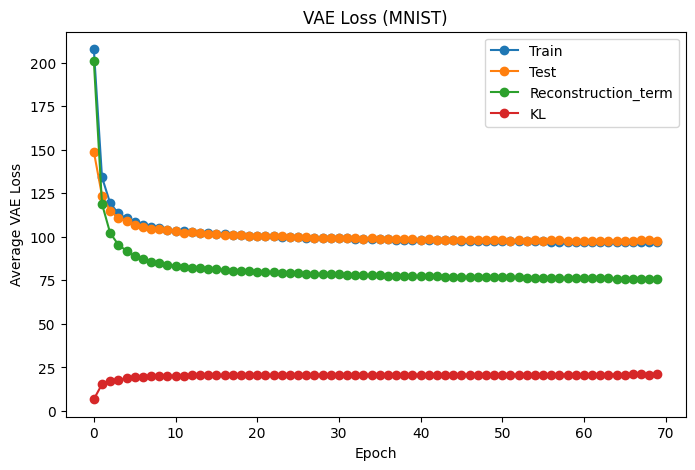

In [32]:
plt.figure(figsize=(8,5))
plt.plot(train_losses_cov1, '-o')
plt.plot(test_losses_cov1, '-o')
plt.plot(train_bce_losses_cov1, '-o')
plt.plot(train_kld_losses_cov1, '-o')

plt.xlabel("Epoch")
plt.ylabel("Average VAE Loss")
plt.title("VAE Loss (MNIST)")
plt.legend(["Train", "Test", "Reconstruction_term", "KL"])
plt.savefig(output_dir + 'VAE_training_loss_conv1.png')
plt.show()

In [33]:
output_dir_cov1 = '/content/drive/MyDrive/Imperial College London/PGM/CW2/datasets/results/VAE_MNIST/'
os.makedirs(output_dir_cov1, exist_ok=True)

torch.save(model_cov1.state_dict(), output_dir_cov1+ 'model_weights_cov1.pth')

In [36]:
my_model_cov1 = ConvVAE1().to(device)
state_cov1 = torch.load('/content/drive/MyDrive/Imperial College London/PGM/CW2/datasets/results/VAE_MNIST/' + "model_weights_cov1.pth", map_location=device, weights_only=False)
my_model_cov1.load_state_dict(state_cov1)
my_model_cov1.eval()

ConvVAE1(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (fc_encode): Linear(in_features=1024, out_features=128, bias=True)
  (fc_mu): Linear(in_features=128, out_features=20, bias=True)
  (fc_logvar): Linear(in_features=128, out_features=20, bias=True)
  (fc_decode): Linear(in_features=20, out_features=128, bias=True)
  (fc_upsample): Linear(in_features=128, out_features=1024, bias=True)
  (deconv0): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (deconv1): ConvTranspose2d(32, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  (deconv2): ConvTranspose2d(16, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
)

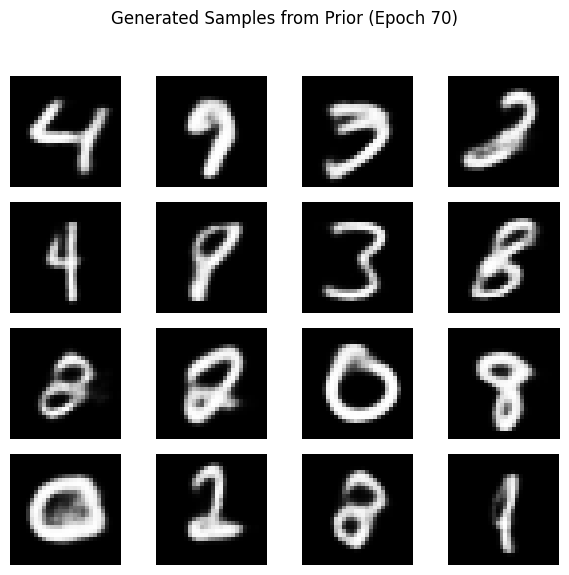

In [37]:
epoch = 70

sample = torch.randn(16, 20).to(device)
sample = my_model_cov1.decode(sample).cpu()
save_image(sample.view(16, 1, 28, 28), output_dir_cov1 + 'sample_' + str(epoch) + '.png')

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
axes = axes.flatten()

for i in range(16):
    ax = axes[i]
    img = sample[i].view(28, 28).detach().numpy()
    ax.imshow(img, cmap='gray')
    ax.axis('off')

plt.suptitle('Generated Samples from Prior (Epoch ' + str(epoch) + ')')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(output_dir_cov1 + 'prior_convvae1')
plt.show()

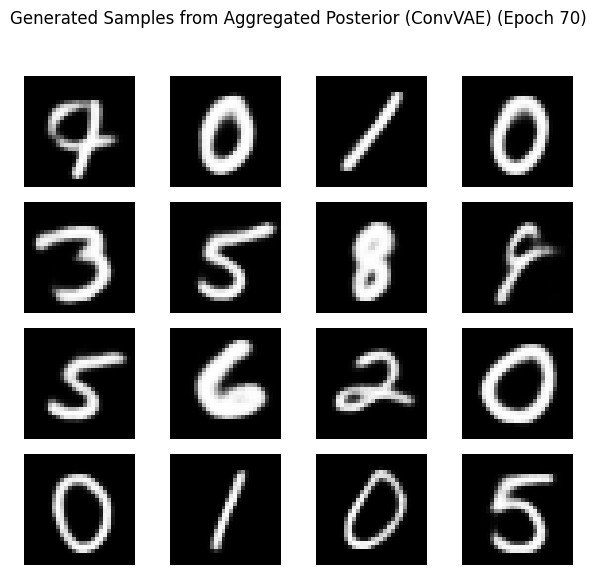

In [38]:
sample_input_cov1 = sample_a.to(device) # sample_a is already (16, 1, 28, 28)
_, mu, logvar = my_model_cov1(sample_input_cov1)
z = mu + torch.exp(0.5*logvar) * torch.randn_like(mu)
z = my_model_cov1.decode(z) # Use my_model_cov for decoding

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
axes = axes.flatten()

for i in range(16):
    ax = axes[i]
    img = z[i].view(28, 28).detach().cpu().numpy()
    ax.imshow(img, cmap='gray')
    ax.axis('off')

plt.suptitle('Generated Samples from Aggregated Posterior (ConvVAE) (Epoch ' + str(epoch) + ')')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(output_dir + 'aggregated posterior_convvae1')
plt.show()

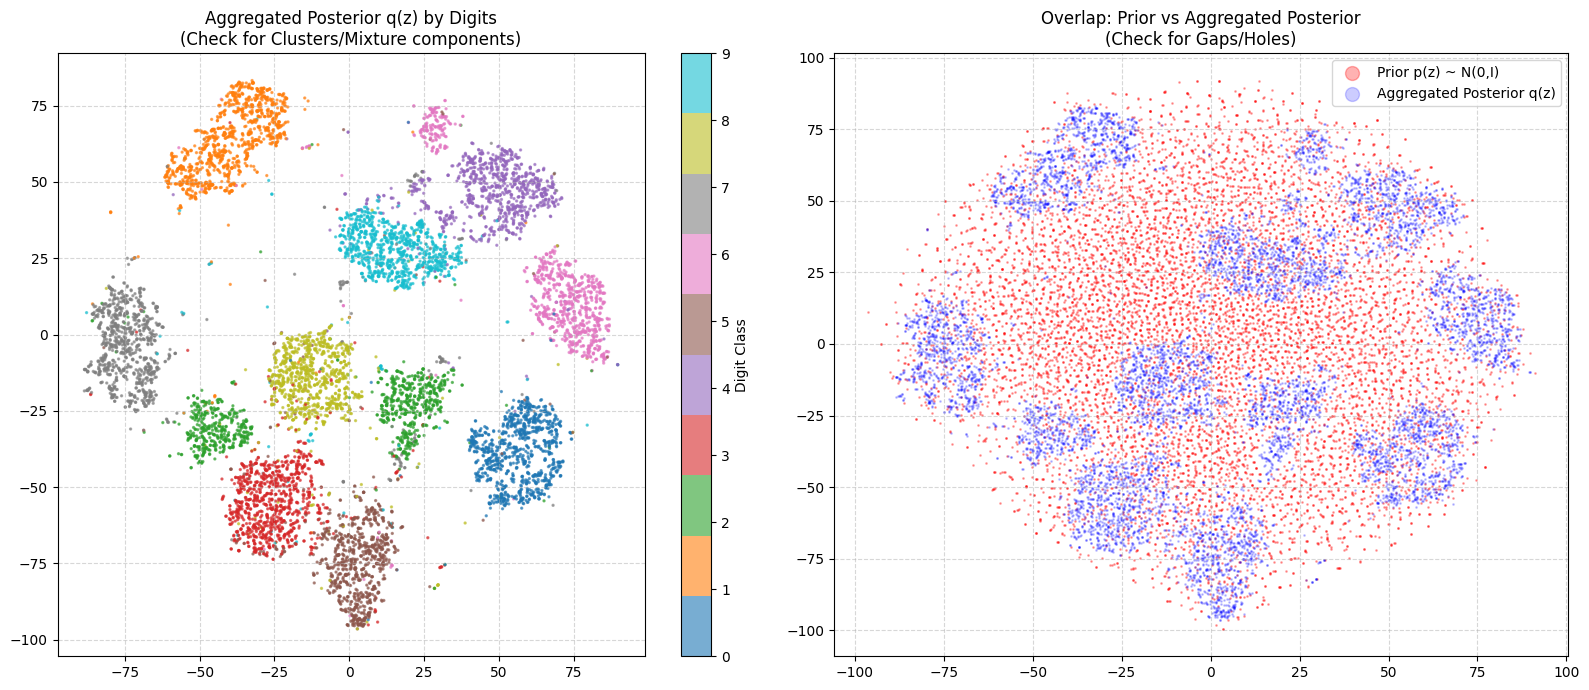

In [39]:
from sklearn.manifold import TSNE
import numpy as np

my_model_cov1.eval()
all_z = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        mu, logvar = my_model_cov1.encode(images)
        all_z.append(mu.cpu())
        all_labels.append(labels)

z_posterior = torch.cat(all_z, dim=0).numpy()
labels = torch.cat(all_labels, dim=0).numpy()

z_prior = torch.randn(len(z_posterior), 20).numpy()

z_combined = np.vstack([z_posterior, z_prior])
tsne = TSNE(n_components=2, init='pca', random_state=42)
z_2d = tsne.fit_transform(z_combined)

z_posterior_2d = z_2d[:len(z_posterior)]
z_prior_2d = z_2d[len(z_posterior):]


plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)
scatter = plt.scatter(z_posterior_2d[:, 0], z_posterior_2d[:, 1],
                      c=labels, cmap='tab10', s=2, alpha=0.6)
plt.colorbar(scatter, label='Digit Class')
plt.title('Aggregated Posterior q(z) by Digits\n(Check for Clusters/Mixture components)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)

plt.scatter(z_prior_2d[:, 0], z_prior_2d[:, 1],
            c='red', s=1, alpha=0.3, label='Prior p(z) ~ N(0,I)')

plt.scatter(z_posterior_2d[:, 0], z_posterior_2d[:, 1],
            c='blue', s=1, alpha=0.2, label='Aggregated Posterior q(z)')
plt.legend(markerscale=10)
plt.title('Overlap: Prior vs Aggregated Posterior\n(Check for Gaps/Holes)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(output_dir + 'prior_vs_posterior_convvae1.png')
plt.show()

In [54]:
mu_set = []
var_set = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        mu, logvar = my_model_cov1.encode(images)
        var = torch.exp(logvar)
        mu_set.append(mu.cpu())
        var_set.append(var.cpu())

mu_set = torch.cat(mu_set, dim=0)
var_set = torch.cat(var_set, dim=0)

posterior_mean = torch.mean(mu_set, dim=0)

# varz = E(var(z|x))+var(E(z|x))
p1 = torch.mean(var_set, dim=0)
p2 = torch.var(mu_set, dim=0)

posterior_var = p1 + p2
sum_posterior_var = torch.mean(posterior_var)

print(f"The mean of posterior mean is")
print(posterior_mean.numpy())
print(f"The distance of mean is {torch.sum(posterior_mean ** 2)}")
print(f"The var of posterior variance is")
print(posterior_var.numpy())
print(f"The mean of posterior_var is {sum_posterior_var.numpy()}")

wasserstein_metric = wasserstein (posterior_mean, posterior_var)
print(f"The Wassersstein is {wasserstein_metric}")

The mean of posterior mean is
[-0.093054    0.00625571 -0.00389734  0.00126748  0.02731025 -0.01718597
 -0.04412217 -0.01064151 -0.07561856  0.02922285  0.01184743 -0.03742606
  0.06372627  0.00601313 -0.10676521 -0.03882993 -0.04444023 -0.00381313
 -0.00903085 -0.04071292]
The distance of mean is 0.04066174477338791
The var of posterior variance is
[0.9453003  1.0073878  0.9943444  1.0101101  0.98471546 0.9887493
 1.0182846  0.97011185 0.9538808  0.96526474 0.99008036 0.9860729
 1.0295919  0.9974593  0.9308341  0.9772375  0.96508414 0.9888741
 1.0056069  0.994467  ]
The mean of posterior_var is 0.9851729273796082
The Wassersstein is 8.155152320861816


In [41]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ConvVAE2(nn.Module):
    def __init__(self):
        super(ConvVAE2, self).__init__()


        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=2, padding=1)  # Output: 16 x 14 x 14
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=2, padding=1) # Output: 32 x 7 x 7
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=2, padding=1) # Output: 64 x 4 x 4
        self.conv4 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=2, padding=1)# Output: 128 x 2 x 2

        self.fc_encode = nn.Linear(128 * 2 * 2, 128)
        self.fc_mu = nn.Linear(128, 20)
        self.fc_logvar = nn.Linear(128, 20)


        self.fc_decode = nn.Linear(20, 128)
        self.fc_upsample = nn.Linear(128, 128 * 2 * 2)

        self.deconv1 = nn.ConvTranspose2d(in_channels=128, out_channels=64, kernel_size=3, stride=2, padding=1, output_padding=1) # Output: 64 x 4 x 4
        self.deconv2 = nn.ConvTranspose2d(in_channels=64, out_channels=32, kernel_size=3, stride=2, padding=1, output_padding=0)  # Output: 32 x 7 x 7
        self.deconv3 = nn.ConvTranspose2d(in_channels=32, out_channels=16, kernel_size=3, stride=2, padding=1, output_padding=1)  # Output: 16 x 14 x 14
        self.deconv4 = nn.ConvTranspose2d(in_channels=16, out_channels=1, kernel_size=3, stride=2, padding=1, output_padding=1)   # Output: 1 x 28 x 28

    def encode(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = x.view(-1, 128 * 2 * 2)
        x = F.relu(self.fc_encode(x))
        return self.fc_mu(x), self.fc_logvar(x)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        z = F.relu(self.fc_decode(z))
        z = F.relu(self.fc_upsample(z))
        z = z.view(-1, 128, 2, 2)
        z = F.relu(self.deconv1(z))
        z = F.relu(self.deconv2(z))
        z = F.relu(self.deconv3(z))
        return torch.sigmoid(self.deconv4(z))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        self.mu = mu
        self.logvar = logvar
        return self.decode(z).view(-1, 28 * 28), mu, logvar

In [42]:
model_cov2 = ConvVAE2().to(device)
optimizer = optim.Adam(model_cov2.parameters(), lr=1e-3)

In [43]:
train_losses_cov2 = []
train_bce_losses_cov2 = []
train_kld_losses_cov2 = []
test_losses_cov2 = []

start_time = time.time()

for epoch in range(1, args.epochs + 1):
    avg_loss_cov2, avg_bce_loss_cov2, avg_kld_loss_cov2 = train(epoch, model_cov2)
    train_losses_cov2.append(avg_loss_cov2)
    train_bce_losses_cov2.append(avg_bce_loss_cov2)
    train_kld_losses_cov2.append(avg_kld_loss_cov2)
    test_loss_cov2 = test(epoch, model_cov2)
    test_losses_cov2.append(test_loss_cov2)

    print('====> Epoch: {} Average loss: {:.4f} Test loss {}'.format(
          epoch, avg_loss_cov2, test_loss_cov2))
end_time = time.time()
total_seconds = end_time - start_time
print(f"Total time: {total_seconds:.2f}s")

====> Epoch: 1 Average loss: 219.9437 Test loss 183.19910947265626
====> Epoch: 2 Average loss: 158.5573 Test loss 142.6532334716797
====> Epoch: 3 Average loss: 134.7167 Test loss 128.72255561523437
====> Epoch: 4 Average loss: 125.9437 Test loss 123.40305119628906
====> Epoch: 5 Average loss: 121.5738 Test loss 119.586590625
====> Epoch: 6 Average loss: 118.2475 Test loss 116.39460106201172
====> Epoch: 7 Average loss: 115.8694 Test loss 114.83877575683594
====> Epoch: 8 Average loss: 113.9759 Test loss 112.35064555664063
====> Epoch: 9 Average loss: 111.8050 Test loss 110.97639826660156
====> Epoch: 10 Average loss: 110.1606 Test loss 109.2042170288086
====> Epoch: 11 Average loss: 108.7047 Test loss 107.80771888427735
====> Epoch: 12 Average loss: 107.7377 Test loss 107.23140145263672
====> Epoch: 13 Average loss: 106.9823 Test loss 107.44087591552734
====> Epoch: 14 Average loss: 106.4383 Test loss 105.81289367675781
====> Epoch: 15 Average loss: 105.8760 Test loss 105.30534447021

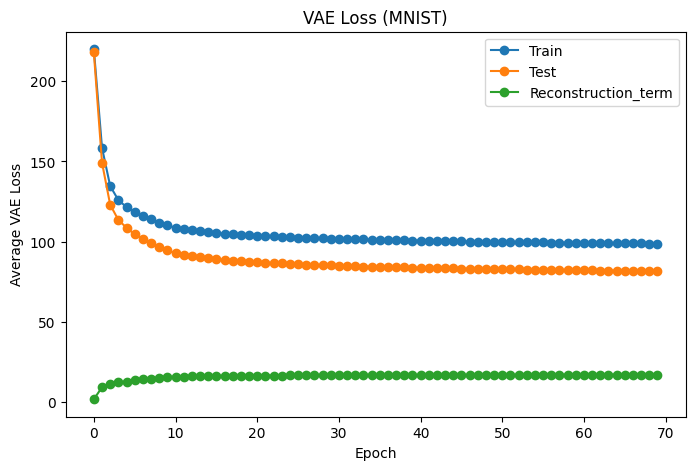

In [45]:
plt.figure(figsize=(8,5))
plt.plot(train_losses_cov2, '-o')
#plt.plot(test_losses_cov2, '-o')
plt.plot(train_bce_losses_cov2, '-o')
plt.plot(train_kld_losses_cov2, '-o')

plt.xlabel("Epoch")
plt.ylabel("Average VAE Loss")
plt.title("VAE Loss (MNIST)")
plt.legend(["Train", "Test", "Reconstruction_term", "KL"])
plt.savefig(output_dir + 'VAE_training_loss_conv2.png')
plt.show()

In [46]:
output_dir_cov2 = '/content/drive/MyDrive/Imperial College London/PGM/CW2/datasets/results/VAE_MNIST/'
os.makedirs(output_dir_cov2, exist_ok=True)

torch.save(model_cov2.state_dict(), output_dir_cov2+ 'model_weights_cov2.pth')

In [48]:
my_model_cov2 = ConvVAE2().to(device)
state_cov2 = torch.load('/content/drive/MyDrive/Imperial College London/PGM/CW2/datasets/results/VAE_MNIST/' + "model_weights_cov2.pth", map_location=device, weights_only=False)
my_model_cov2.load_state_dict(state_cov2)
my_model_cov2.eval()

ConvVAE2(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (conv4): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (fc_encode): Linear(in_features=512, out_features=128, bias=True)
  (fc_mu): Linear(in_features=128, out_features=20, bias=True)
  (fc_logvar): Linear(in_features=128, out_features=20, bias=True)
  (fc_decode): Linear(in_features=20, out_features=128, bias=True)
  (fc_upsample): Linear(in_features=128, out_features=512, bias=True)
  (deconv1): ConvTranspose2d(128, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  (deconv2): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (deconv3): ConvTranspose2d(32, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  (deconv4): ConvTranspose2d(16, 1, 

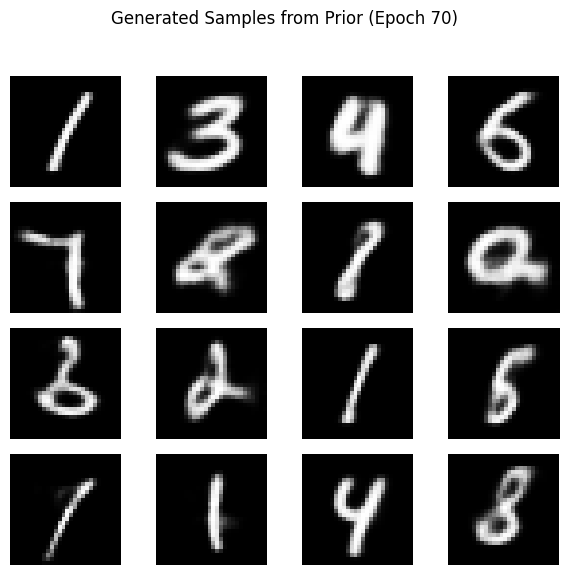

In [49]:
epoch = 70

sample = torch.randn(16, 20).to(device)
sample = my_model_cov2.decode(sample).cpu()
save_image(sample.view(16, 1, 28, 28), output_dir_cov2 + 'sample_' + str(epoch) + '.png')

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
axes = axes.flatten()

for i in range(16):
    ax = axes[i]
    img = sample[i].view(28, 28).detach().numpy()
    ax.imshow(img, cmap='gray')
    ax.axis('off')

plt.suptitle('Generated Samples from Prior (Epoch ' + str(epoch) + ')')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(output_dir_cov2 + 'prior_convvae2')
plt.show()

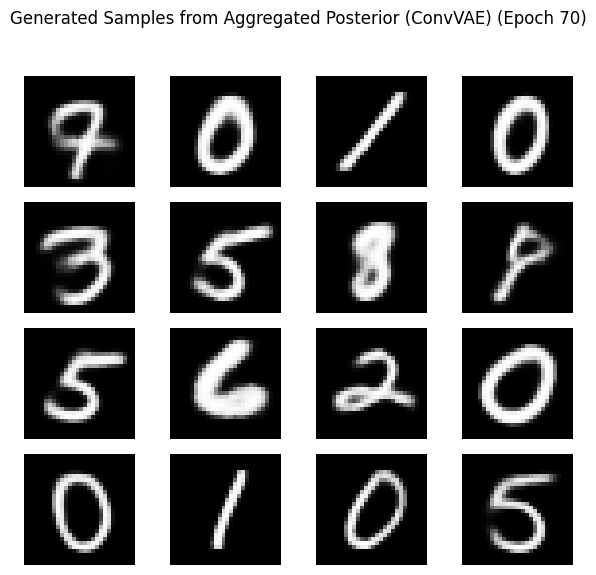

In [50]:
sample_input_cov2 = sample_a.to(device) # sample_a is already (16, 1, 28, 28)
_, mu, logvar = my_model_cov2(sample_input_cov2)
z = mu + torch.exp(0.5*logvar) * torch.randn_like(mu)
z = my_model_cov2.decode(z) # Use my_model_cov for decoding

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
axes = axes.flatten()

for i in range(16):
    ax = axes[i]
    img = z[i].view(28, 28).detach().cpu().numpy()
    ax.imshow(img, cmap='gray')
    ax.axis('off')

plt.suptitle('Generated Samples from Aggregated Posterior (ConvVAE) (Epoch ' + str(epoch) + ')')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(output_dir + 'aggregated posterior_convvae1')
plt.show()

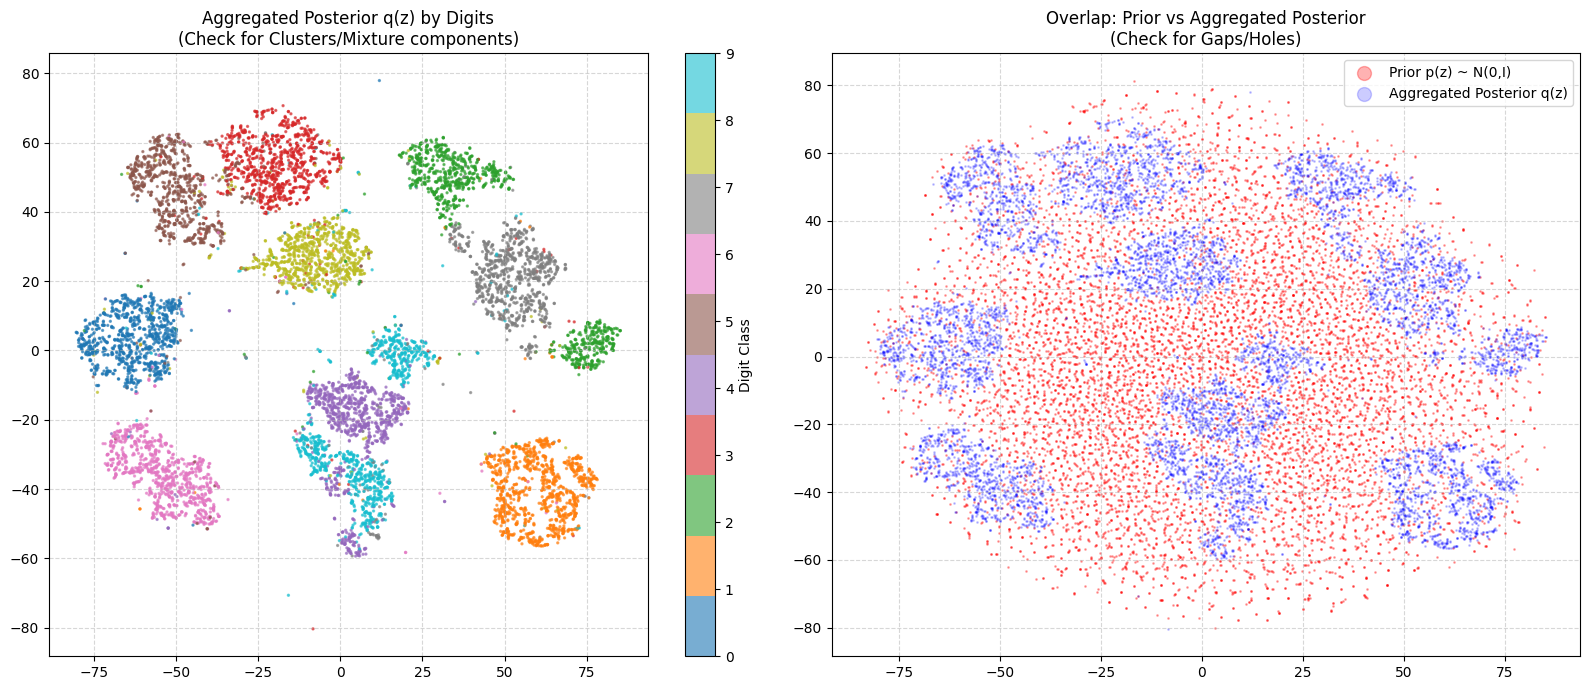

In [52]:
from sklearn.manifold import TSNE
import numpy as np

my_model_cov2.eval()
all_z = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        mu, logvar = my_model_cov2.encode(images)
        all_z.append(mu.cpu())
        all_labels.append(labels)

z_posterior = torch.cat(all_z, dim=0).numpy()
labels = torch.cat(all_labels, dim=0).numpy()

z_prior = torch.randn(len(z_posterior), 20).numpy()

z_combined = np.vstack([z_posterior, z_prior])
tsne = TSNE(n_components=2, init='pca', random_state=42)
z_2d = tsne.fit_transform(z_combined)

z_posterior_2d = z_2d[:len(z_posterior)]
z_prior_2d = z_2d[len(z_posterior):]


plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)
scatter = plt.scatter(z_posterior_2d[:, 0], z_posterior_2d[:, 1],
                      c=labels, cmap='tab10', s=2, alpha=0.6)
plt.colorbar(scatter, label='Digit Class')
plt.title('Aggregated Posterior q(z) by Digits\n(Check for Clusters/Mixture components)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)

plt.scatter(z_prior_2d[:, 0], z_prior_2d[:, 1],
            c='red', s=1, alpha=0.3, label='Prior p(z) ~ N(0,I)')

plt.scatter(z_posterior_2d[:, 0], z_posterior_2d[:, 1],
            c='blue', s=1, alpha=0.2, label='Aggregated Posterior q(z)')
plt.legend(markerscale=10)
plt.title('Overlap: Prior vs Aggregated Posterior\n(Check for Gaps/Holes)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(output_dir + 'prior_vs_posterior_convvae2.png')
plt.show()

In [53]:
mu_set = []
var_set = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        mu, logvar = my_model_cov2.encode(images)
        var = torch.exp(logvar)
        mu_set.append(mu.cpu())
        var_set.append(var.cpu())

mu_set = torch.cat(mu_set, dim=0)
var_set = torch.cat(var_set, dim=0)

posterior_mean = torch.mean(mu_set, dim=0)

# varz = E(var(z|x))+var(E(z|x))
p1 = torch.mean(var_set, dim=0)
p2 = torch.var(mu_set, dim=0)

posterior_var = p1 + p2
sum_posterior_var = torch.mean(posterior_var)

print(f"The mean of posterior mean is")
print(posterior_mean.numpy())
print(f"The distance of mean is {torch.sum(posterior_mean ** 2)}")
print(f"The var of posterior variance is")
print(posterior_var.numpy())
print(f"The mean of posterior_var is {sum_posterior_var.numpy()}")

wasserstein_metric = wasserstein (posterior_mean, posterior_var)
print(f"The Wassersstein is {wasserstein_metric}")

The mean of posterior mean is
[ 2.7169937e-03 -4.6999596e-02 -1.8047928e-03 -2.8789188e-03
 -4.1229101e-03 -1.2276437e-02  1.6277781e-02 -7.8675328e-03
 -9.0624541e-03 -2.3398019e-02  6.6045918e-02 -3.9434541e-02
 -1.1639180e-02  7.8910736e-05 -1.6433610e-02 -3.1440654e-03
  1.2564242e-03  1.7884353e-02 -9.2673581e-03  1.2335649e-02]
The distance of mean is 0.010244110599160194
The var of posterior variance is
[0.962907   0.9766014  0.96964264 0.97576565 1.0003272  0.96885
 0.9763086  0.98505366 1.0385131  0.96952915 0.9726639  0.95997316
 0.97333837 0.98425746 1.0107158  1.0056976  0.98370475 1.0038459
 0.9989708  1.001101  ]
The mean of posterior_var is 0.9858883619308472
The Wassersstein is 8.135811805725098
